# 11장 · OpenAI Responses API의 요청·응답 구조

SDK는 Python에서 요청을 만들고 응답을 읽게 해 주는 라이브러리입니다. 고정 응답으로도 메시지, 출력 본문, 사용량 필드를 따로 살펴볼 수 있습니다.

화면에서는 한 줄 답변이 보이지만 프로그램이 받는 응답에는 모델 이름, 완료 상태, 사용량도 들어 있습니다. 한 번의 요청을 준비하고 수업용 응답을 받아 보낸 질문과 돌려받은 답, 사용량이 각각 어디에 남는지 확인합니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 httpx 0.28.1, openai 3.35.1입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 사용자 메시지의 role과 content

SDK는 파이썬 코드에서 서비스의 요청과 응답을 다루게 해 주는 라이브러리입니다. 먼저 보내려는 내용만 조립하면 실제 통신 없이도 모델 이름과 사용자 메시지가 어느 칸에 들어 있는지 볼 수 있습니다.


### 셀 01 · role과 content 구성

model은 예제의 대역 이름입니다. 실제 계정에서 선택할 모델과 구분하세요.


In [1]:
question = "SDK가 하는 일을 한 문장으로 설명하세요."
request = {"model": "classroom-mock", "input": [{"role": "user", "content": question}], "max_output_tokens": 300}
print(request["input"][0]["content"])

SDK가 하는 일을 한 문장으로 설명하세요.


원래 질문이 그대로 나옵니다. max_output_tokens는 생성할 출력의 한도이고 입력 문장 길이나 실제 생성 토큰 수가 아닙니다.


## MockTransport를 이용한 SDK 호출

아래는 제공 셀입니다. OpenAI SDK와 HTTPX가 설치된 커널에서는 SDK의 responses.create를 실제로 호출합니다. 전송은 로컬의 MockTransport가 받아 고정 응답을 돌려주므로 계정과 모델 서버를 쓰지 않습니다.

<!-- lesson-visual visual-sdk-mock -->
**모의 전송에서 답변이 돌아오기까지**

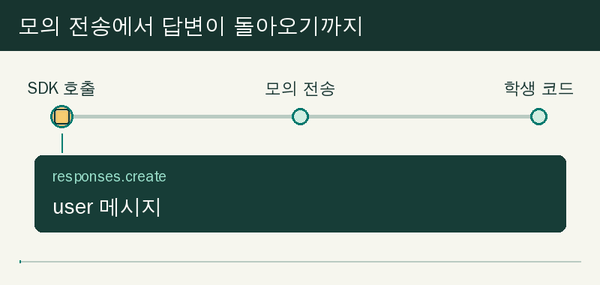

MockTransport가 요청 본문을 받은 뒤 수업용 응답을 반환합니다. 마지막에 학생 코드가 읽는 값은 response.output_text입니다.
<!-- /lesson-visual visual-sdk-mock -->


### 셀 02 · 모의 SDK 응답 생성

제공 함수는 요청에서 user 역할을 확인하고, message 하나와 사용량 예시가 든 HTTP 응답을 준비합니다.

제공 함수는 네트워크 대신 예제 응답을 만듭니다. 셀 03에서는 본문을, 과제 04에서는 같은 응답의 사용량을 읽습니다. 처음에는 함수 안의 생성 코드보다 반환된 응답 한 건을 따라가세요.


In [2]:
import json
from importlib.util import find_spec
sdk_available = find_spec("httpx") is not None and find_spec("openai") is not None
if sdk_available:
    import httpx
    from openai import OpenAI

def mock_response(request):
    body = json.loads(request.content)
    assert body["input"][0]["role"] == "user"
    return httpx.Response(200, json={
        "id": "resp_local", "object": "response", "created_at": 0,
        "model": "classroom-mock", "status": "completed",
        "output": [{"id": "msg_local", "type": "message",
                    "role": "assistant", "status": "completed",
                    "content": [{"type": "output_text", "text": "가상 안내를 확인했습니다.", "annotations": []}]}],
        "usage": {"input_tokens": 10, "output_tokens": 8, "total_tokens": 18},
    })

이 셀은 함수를 정의합니다. 아직 요청을 보내지 않았으므로 답변 출력이 없습니다.


### 셀 03 · output_text 읽기

고정 응답에 적힌 안내 문장을 SDK가 꺼낸 값과 대조하세요.


In [3]:
if sdk_available:
    transport = httpx.MockTransport(mock_response)
    with OpenAI(api_key="classroom-placeholder", base_url="https://example.invalid/v1",
                http_client=httpx.Client(transport=transport), max_retries=0) as client:
        response = client.responses.create(**request)
    print(response.output_text)
else:
    print("OpenAI SDK와 HTTPX가 설치된 수업 커널에서 모의 호출을 실행하세요.")

가상 안내를 확인했습니다.


SDK가 꺼낸 본문은 ‘가상 안내를 확인했습니다.’입니다. 이 문장은 제공 함수의 응답 본문에서 왔습니다. 실제 서비스 모델의 생성 결과나 품질을 보여 주지는 않습니다.


## usage와 응답 완료 상태

토큰은 모델이 입력과 출력을 세는 단위입니다. 과금이나 지연을 추측하지 않고 응답에 실제 제공된 값을 읽습니다. 요청 상태가 미완료면 본문 길이만 보고 성공으로 기록하지 않습니다.


### 과제 04 · usage의 토큰 합계

제공 응답과 같은 사용량 사전입니다. 사용량이 보고된 경우 총 토큰 수를 출력하세요.


In [4]:
usage = {"input_tokens": 10, "output_tokens": 8, "total_tokens": 18}
# 응답의 총량을 꺼내세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>usage = {&quot;input_tokens&quot;: 10, &quot;output_tokens&quot;: 8, &quot;total_tokens&quot;: 18}
print(usage[&quot;total_tokens&quot;])</code></pre>
<p>실행 결과</p><pre><code>18</code></pre>
<p>18은 제공 응답에 넣어 둔 수치입니다. 실제 요청의 경우에는 모델·입력마다 달라지며 사용량이 빠진 경우도 따로 남깁니다.</p>
</details>


### 셀 05 · 미완료 상태 판별

통신은 끝났지만 서비스가 완료하지 못했다고 가정합니다. 본문을 화면에 내보내도 될까요?


In [5]:
partial = {"status": "incomplete", "text": "가상 안"}
if partial["status"] == "completed":
    print(partial["text"])
else:
    print("미완료 응답")

미완료 응답


‘미완료 응답’이 남습니다. 실제 호출 기록에는 모델, 상태, 사용량과 경과 시간을 구분해 두고 오류가 나면 키나 요청 원문 전체 대신 필요한 오류 종류를 기록합니다.


## 돌아보기

질문 하나의 입력, 응답 본문, 사용량을 다시 짚어 보세요. 같은 글자를 요청해도 라이브 응답의 값은 달라질 수 있습니다. 다음 장에서는 완료 응답을 받았을 때도 그 안의 공지 형식과 내용을 다시 확인합니다.
